# 32. End-to-End NLP Pipeline

## Overview
A text-processing pipeline connects preprocessing, feature extraction, model training, evaluation, and inference into a reproducible workflow. This notebook builds a compact text classification pipeline with scikit-learn and demonstrates how to save and reload it.

The example uses synthetic labeled texts; the same structure can be adapted to a real dataset.

## 1. Import libraries

In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

## 2. Prepare labeled documents

In [2]:
data = [
    ("The application is fast and easy to use", "positive"),
    ("I am happy with the excellent service", "positive"),
    ("The tool works perfectly for my needs", "positive"),
    ("Great design and reliable performance", "positive"),
    ("The support team solved my problem quickly", "positive"),
    ("This product is useful and well designed", "positive"),
    ("The application crashes and loses my work", "negative"),
    ("Poor performance and very frustrating errors", "negative"),
    ("The service was slow and unhelpful", "negative"),
    ("I am disappointed with this unreliable tool", "negative"),
    ("The update broke several important features", "negative"),
    ("The interface is confusing and difficult", "negative"),
    ("The package contains a setup guide", "neutral"),
    ("The software version is listed in the menu", "neutral"),
    ("The report was created on Tuesday", "neutral"),
    ("The device has four ports", "neutral"),
    ("The file contains a list of records", "neutral"),
    ("The meeting is scheduled for next week", "neutral"),
]

df = pd.DataFrame(data, columns=["text", "label"])
display(df.groupby("label").size().rename("count").to_frame())

,count
label,
negative,6
neutral,6
positive,6


## 3. Split the data

Keep test data separate from model fitting. Stratification maintains class proportions where possible.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    df["text"],
    df["label"],
    test_size=0.33,
    random_state=21,
    stratify=df["label"],
)

## 4. Define the end-to-end pipeline

The pipeline keeps TF-IDF vocabulary fitting inside the training process, reducing the risk of data leakage.

In [4]:
nlp_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(ngram_range=(1, 2), lowercase=True)),
    ("classifier", LogisticRegression(max_iter=1000, random_state=21)),
])

nlp_pipeline.fit(X_train, y_train)
print("Pipeline trained.")

Pipeline trained.


## 5. Evaluate the pipeline

Accuracy: 0.333
              precision    recall  f1-score   support

    negative       0.00      0.00      0.00         2
     neutral       0.67      1.00      0.80         2
    positive       0.00      0.00      0.00         2

    accuracy                           0.33         6
   macro avg       0.22      0.33      0.27         6
weighted avg       0.22      0.33      0.27         6



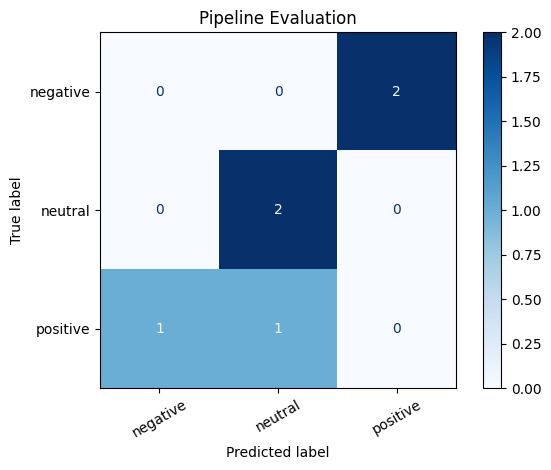

In [5]:
y_pred = nlp_pipeline.predict(X_test)

print(f"Accuracy: {accuracy_score(y_test, y_pred):.3f}")
print(classification_report(y_test, y_pred, zero_division=0))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=["negative", "neutral", "positive"],
    cmap="Blues",
    xticks_rotation=30,
)
plt.title("Pipeline Evaluation")
plt.tight_layout()
plt.show()

## 6. Create a reusable inference function

A small wrapper provides a stable interface for classifying one string or a list of strings.

In [6]:
def predict_texts(texts, pipeline=nlp_pipeline):
    if isinstance(texts, str):
        texts = [texts]
    labels = pipeline.predict(texts)
    return pd.DataFrame({"text": texts, "predicted_label": labels})

new_texts = [
    "The new version is excellent and very reliable",
    "The application freezes and the service is terrible",
    "The file contains five columns",
]

display(predict_texts(new_texts))

,text,predicted_label
0,The new version is excellent and very reliable,neutral
1,The application freezes and the service is ter...,negative
2,The file contains five columns,neutral


## 7. Save and reload the trained pipeline

Joblib serializes the fitted vectorizer and classifier together. Only load model files from trusted sources.

In [7]:
from pathlib import Path
import joblib

model_path = Path("text_classification_pipeline.joblib")
joblib.dump(nlp_pipeline, model_path)

loaded_pipeline = joblib.load(model_path)
print("Saved to:", model_path.resolve())
print("Reloaded predictions:", loaded_pipeline.predict(new_texts))

Saved to: /home/mg/Desktop/projects/nlp-learning/07_projects/text_classification_pipeline.joblib
Reloaded predictions: ['neutral' 'negative' 'neutral']


## 8. Inspect the learned vocabulary and coefficients

For linear classifiers, coefficients can provide a rough view of which features are associated with each class. They are not causal explanations.

In [8]:
feature_names = nlp_pipeline.named_steps["tfidf"].get_feature_names_out()
classifier = nlp_pipeline.named_steps["classifier"]

coefficient_rows = []
for class_index, class_label in enumerate(classifier.classes_):
    top_indices = classifier.coef_[class_index].argsort()[-10:][::-1]
    for rank, feature_index in enumerate(top_indices, start=1):
        coefficient_rows.append({
            "class": class_label,
            "rank": rank,
            "feature": feature_names[feature_index],
            "coefficient": classifier.coef_[class_index][feature_index],
        })

coefficients_df = pd.DataFrame(coefficient_rows)
display(coefficients_df)

,class,rank,feature,coefficient
0,negative,1,the interface,0.168690
1,negative,2,difficult,0.168690
2,negative,3,interface is,0.168690
3,negative,4,interface,0.168690
4,negative,5,is confusing,0.168690
5,negative,6,confusing and,0.168690
6,negative,7,and difficult,0.168690
7,negative,8,confusing,0.168690
8,negative,9,slow,0.163812
9,negative,10,the service,0.163812


## Production considerations

- Replace the illustrative data with a representative labeled dataset.
- Use cross-validation for model selection and keep a final test set untouched.
- Version datasets, preprocessing rules, and trained models.
- Monitor prediction quality and data drift after deployment.
- For sensitive applications, review privacy, fairness, and error costs before deployment.

## Summary

This notebook demonstrates a reusable NLP workflow: split labeled text, fit a TF-IDF/classifier pipeline, evaluate predictions, run inference, and persist the complete model.